In [ ]:
# Importamos la biblioteca de pandas para la lectura del .csv. Le damos el alias de pd
import pandas as pd

melb_df = pd.read_csv('dataset_consumo_electrico_30000.csv')
display(melb_df.head())

,id_registro,edad_vivienda_anios,superficie_m2,numero_personas,habitaciones,dias_facturacion,temperatura_media_c,temperatura_minima_c,temperatura_maxima_c,mes,...,tipo_agua_caliente,aire_acondicionado,paneles_solares,numero_electrodomesticos,teletrabajo,nivel_ocupacion_diurna,potencia_contratada_kw,tipo_tarifa,anio,consumo_mensual_kwh
0,1,86,175.2,2.0,5.0,31.0,10.3,5.3,21.9,3,...,Gas,No,No,7.0,No,Media,3.41,Fija,2026,601.7
1,2,18,146.6,3.0,5.0,31.0,8.2,-1.9,12.0,7,...,Gas,No,No,10.0,No,Alta,5.23,Fija,2021,731.6
2,3,2,103.8,4.0,2.0,30.0,19.8,7.2,25.0,12,...,Solar,Sí,No,8.0,Sí,Alta,4.54,Fija,2023,499.2
3,4,64,85.0,5.0,3.0,31.0,19.9,12.3,29.3,1,...,Gas,Sí,No,9.0,No,Alta,4.87,Fija,2023,721.2
4,5,36,74.8,2.0,1.0,30.0,9.7,1.8,13.8,5,...,Solar,No,No,4.0,No,Media,2.74,Fija,2023,314.8


In [ ]:
from sklearn.model_selection import train_test_split

# Elegimos las siete variables predictoras del conjunto amplio
variables = [
    "superficie_m2",
    "numero_personas",
    "tipo_calefaccion",
    "aire_acondicionado",
    "nivel_aislamiento",
    "temperatura_media_c",
    "numero_electrodomesticos"
]

# 2. Conservar las columnas necesarias y eliminar filas incompletas
datos = melb_df[variables + ["consumo_mensual_kwh"]].dropna()

# 3. Separar predictores y consumo que queremos predecir
x = datos[variables].copy()
consumo_mensual_kwh = datos["consumo_mensual_kwh"].copy()

# 4. Dividir: 70 % para entrenar y 30 % para test
train_x, test_x, train_y, test_y = train_test_split(
    x,
    consumo_mensual_kwh,
    test_size=0.30,
    random_state=42
)

# 5. Convertir los textos a columnas numéricas
train_x = pd.get_dummies(train_x, dtype=int)
test_x = pd.get_dummies(test_x, dtype=int)

# 6. Asegurar las mismas columnas y el mismo orden
test_x = test_x.reindex(
    columns=train_x.columns,
    fill_value=0
)

# 7. Comprobar los datos preparados
print("Viviendas para entrenar:", len(train_x))
print("Viviendas para test:", len(test_x))

display(train_x.head())

Viviendas para entrenar: 20981
Viviendas para test: 8993


,superficie_m2,numero_personas,temperatura_media_c,numero_electrodomesticos,tipo_calefaccion_Biomasa,tipo_calefaccion_Bomba de calor,tipo_calefaccion_Eléctrica,tipo_calefaccion_Gas,tipo_calefaccion_Ninguna,aire_acondicionado_No,aire_acondicionado_Sí,nivel_aislamiento_Alto,nivel_aislamiento_Bajo,nivel_aislamiento_Medio
29802,128.5,3.0,21.2,9.0,0,1,0,0,0,0,1,0,1,0
12932,154.6,5.0,15.3,10.0,0,0,0,0,1,1,0,0,0,1
27090,53.8,4.0,18.8,9.0,0,0,0,1,0,1,0,0,1,0
27642,108.1,3.0,21.5,9.0,0,0,0,0,1,0,1,1,0,0
24006,179.6,2.0,8.4,8.0,0,0,0,0,1,0,1,0,0,1


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Crear los cuatro modelos
modelos = {
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

# Entrenar la regresión lineal
modelos["Regresión lineal"].fit(train_x, train_y)
print("Regresión lineal entrenada.")

# Entrenar el árbol de decisión
modelos["Árbol de decisión"].fit(train_x, train_y)
print("Árbol de decisión entrenado.")

# Entrenar Random Forest
modelos["Random Forest"].fit(train_x, train_y)
print("Random Forest entrenado.")

# Entrenar Gradient Boosting
modelos["Gradient Boosting"].fit(train_x, train_y)
print("Gradient Boosting entrenado.")

Regresión lineal entrenada.
Árbol de decisión entrenado.
Random Forest entrenado.
Gradient Boosting entrenado.


In [4]:
from sklearn.metrics import mean_absolute_error

resultados = []
predicciones_modelos = {}

for nombre, modelo in modelos.items():

    # Predecir el consumo de las viviendas de test
    predicciones = modelo.predict(test_x)

    # Guardar las predicciones para consultarlas después
    predicciones_modelos[nombre] = predicciones

    # Comparar las predicciones con los consumos reales
    mae = mean_absolute_error(test_y, predicciones)

    resultados.append({
        "Modelo": nombre,
        "MAE (kWh)": mae
    })

# Crear una tabla ordenada de menor a mayor error
tabla_resultados = pd.DataFrame(resultados)

tabla_resultados = tabla_resultados.sort_values(
    "MAE (kWh)"
).reset_index(drop=True)

display(tabla_resultados.round(2))

,Modelo,MAE (kWh)
0,Gradient Boosting,75.46
1,Regresión lineal,75.47
2,Random Forest,79.57
3,Árbol de decisión,108.57


In [5]:
# Crear la tabla con los consumos reales
tabla_predicciones = pd.DataFrame({
    "Consumo real (kWh)": test_y
})

# Añadir las predicciones de cada modelo
for nombre, predicciones in predicciones_modelos.items():
    tabla_predicciones[nombre] = predicciones

# Mostrar diez viviendas de test
display(tabla_predicciones.head(10).round(2))

,Consumo real (kWh),Regresión lineal,Árbol de decisión,Random Forest,Gradient Boosting
22549,725.0,773.93,829.6,781.76,795.83
24435,708.2,622.89,650.9,575.98,610.41
19769,558.9,483.28,519.8,505.15,486.88
13561,430.8,448.55,370.2,492.39,464.06
15525,600.8,610.89,771.3,602.01,608.64
29944,731.5,655.78,721.2,611.71,622.93
1536,607.6,647.61,701.2,623.23,619.37
21394,701.9,630.82,784.7,602.67,621.35
24010,665.6,564.80,397.8,524.26,568.57
25572,576.3,625.62,531.9,589.03,614.62


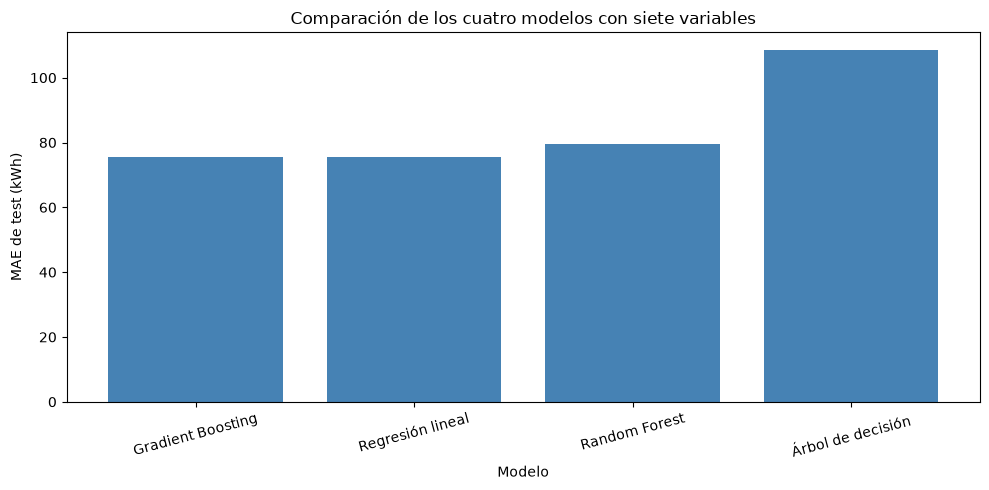

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    tabla_resultados["Modelo"],
    tabla_resultados["MAE (kWh)"],
    color="steelblue"
)

plt.title("Comparación de los cuatro modelos con siete variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [7]:
mejor_modelo = tabla_resultados.iloc[0]["Modelo"]
menor_mae = tabla_resultados.iloc[0]["MAE (kWh)"]

print("Modelo con menor MAE:", mejor_modelo)
print(f"Error absoluto medio: {menor_mae:.2f} kWh")

Modelo con menor MAE: Gradient Boosting
Error absoluto medio: 75.46 kWh


In [8]:
from sklearn.base import clone

# Seleccionar las columnas correspondientes a las cuatro variables.
# Las categóricas ya están convertidas mediante get_dummies().
columnas_reducidas = [
    columna
    for columna in train_x.columns
    if columna in ["superficie_m2", "numero_personas"]
    or columna.startswith("tipo_calefaccion_")
    or columna.startswith("aire_acondicionado_")
]

# Mantener las mismas viviendas de entrenamiento y test
train_x_reducido = train_x[columnas_reducidas].copy()
test_x_reducido = test_x[columnas_reducidas].copy()

print("Variables originales del conjunto reducido: 4")
print("Columnas después de codificar:", len(columnas_reducidas))
print("Viviendas para entrenar:", len(train_x_reducido))
print("Viviendas para test:", len(test_x_reducido))

# Crear modelos nuevos con los mismos parámetros.
# No se modifican los modelos entrenados con siete variables.
modelos_reducidos = {
    nombre: clone(modelo)
    for nombre, modelo in modelos.items()
}

resultados_reducidos = []
predicciones_reducidas = {}

for nombre, modelo in modelos_reducidos.items():

    # Entrenar con las cuatro variables
    modelo.fit(train_x_reducido, train_y)

    # Predecir sobre las mismas viviendas de test
    predicciones = modelo.predict(test_x_reducido)

    # Guardar las predicciones
    predicciones_reducidas[nombre] = predicciones

    # Calcular el MAE
    mae = mean_absolute_error(test_y, predicciones)

    resultados_reducidos.append({
        "Modelo": nombre,
        "MAE (kWh)": mae
    })

tabla_resultados_reducidos = pd.DataFrame(resultados_reducidos)

tabla_resultados_reducidos = (
    tabla_resultados_reducidos
    .sort_values("MAE (kWh)")
    .reset_index(drop=True)
)

print("\nResultados con cuatro variables:")
display(tabla_resultados_reducidos.round(2))

Variables originales del conjunto reducido: 4
Columnas después de codificar: 9
Viviendas para entrenar: 20981
Viviendas para test: 8993

Resultados con cuatro variables:


,Modelo,MAE (kWh)
0,Regresión lineal,82.84
1,Gradient Boosting,83.05
2,Random Forest,95.46
3,Árbol de decisión,117.49


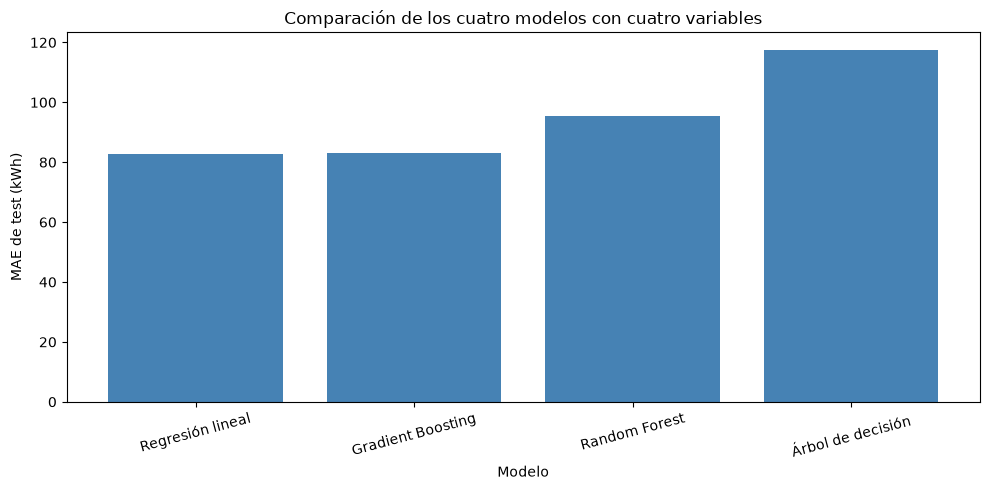

In [11]:
import matplotlib.pyplot as plt

# Ordenar los modelos de menor a mayor MAE
datos_grafico = tabla_resultados_reducidos.sort_values("MAE (kWh)")

plt.figure(figsize=(10, 5))

plt.bar(
    datos_grafico["Modelo"],
    datos_grafico["MAE (kWh)"],
    color="steelblue"
)

plt.title("Comparación de los cuatro modelos con cuatro variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.show()

In [9]:
# Preparar la tabla de cuatro variables
tabla_4 = tabla_resultados_reducidos.rename(
    columns={"MAE (kWh)": "MAE con 4 variables (kWh)"}
)

# Preparar la tabla de siete variables
tabla_7 = tabla_resultados.rename(
    columns={"MAE (kWh)": "MAE con 7 variables (kWh)"}
)

# Unir por nombre de modelo
tabla_comparacion = pd.merge(
    tabla_4,
    tabla_7,
    on="Modelo",
    validate="one_to_one"
)

# Diferencia positiva: siete variables reducen el error.
# Diferencia negativa: siete variables aumentan el error.
tabla_comparacion["Reducción del MAE (kWh)"] = (
    tabla_comparacion["MAE con 4 variables (kWh)"]
    - tabla_comparacion["MAE con 7 variables (kWh)"]
)

# Evitar divisiones por cero al calcular el porcentaje
mae_4 = tabla_comparacion["MAE con 4 variables (kWh)"]

tabla_comparacion["Mejora del MAE (%)"] = (
    tabla_comparacion["Reducción del MAE (kWh)"]
    / mae_4.where(mae_4 != 0)
    * 100
)

tabla_comparacion = tabla_comparacion.sort_values(
    "MAE con 7 variables (kWh)"
).reset_index(drop=True)

display(tabla_comparacion.round(2))

,Modelo,MAE con 4 variables (kWh),MAE con 7 variables (kWh),Reducción del MAE (kWh),Mejora del MAE (%)
0,Gradient Boosting,83.05,75.46,7.59,9.13
1,Regresión lineal,82.84,75.47,7.37,8.89
2,Random Forest,95.46,79.57,15.89,16.64
3,Árbol de decisión,117.49,108.57,8.92,7.59


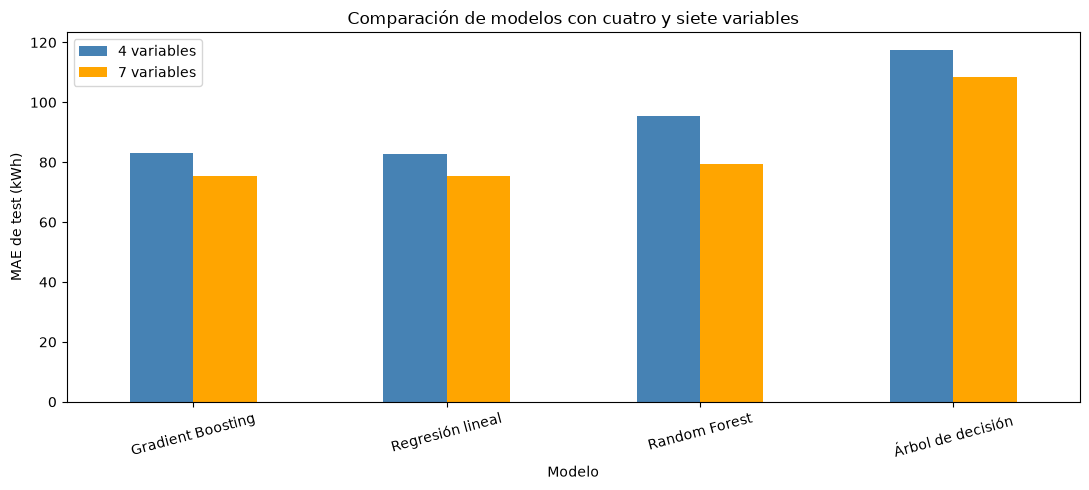

Resultados de las ocho combinaciones:


,Modelo,Conjunto,MAE (kWh)
0,Gradient Boosting,7 variables,75.46
1,Regresión lineal,7 variables,75.47
2,Random Forest,7 variables,79.57
3,Regresión lineal,4 variables,82.84
4,Gradient Boosting,4 variables,83.05
5,Random Forest,4 variables,95.46
6,Árbol de decisión,7 variables,108.57
7,Árbol de decisión,4 variables,117.49


Combinación con menor MAE observado:
Modelo: Gradient Boosting
Conjunto: 7 variables
MAE: 75.46 kWh


In [10]:
# Gráfico de los cuatro algoritmos con ambos conjuntos
tabla_comparacion.set_index("Modelo")[
    [
        "MAE con 4 variables (kWh)",
        "MAE con 7 variables (kWh)"
    ]
].plot(
    kind="bar",
    figsize=(11, 5),
    color=["steelblue", "orange"]
)

plt.title("Comparación de modelos con cuatro y siete variables")
plt.xlabel("Modelo")
plt.ylabel("MAE de test (kWh)")
plt.xticks(rotation=15)
plt.legend(["4 variables", "7 variables"])
plt.tight_layout()
plt.show()

# Tabla con las ocho combinaciones
tabla_global = pd.concat(
    [
        tabla_resultados_reducidos.assign(Conjunto="4 variables"),
        tabla_resultados.assign(Conjunto="7 variables")
    ],
    ignore_index=True
)

tabla_global = (
    tabla_global[["Modelo", "Conjunto", "MAE (kWh)"]]
    .sort_values("MAE (kWh)")
    .reset_index(drop=True)
)

print("Resultados de las ocho combinaciones:")
display(tabla_global.round(2))

# Mejor combinación según el MAE de esta evaluación
mejor_combinacion = tabla_global.iloc[0]

print("Combinación con menor MAE observado:")
print("Modelo:", mejor_combinacion["Modelo"])
print("Conjunto:", mejor_combinacion["Conjunto"])
print(f"MAE: {mejor_combinacion['MAE (kWh)']:.2f} kWh")

# Guardar las tablas para utilizarlas en la memoria
tabla_comparacion.to_csv(
    "comparacion_4_y_7_variables.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_global.to_csv(
    "resultados_8_combinaciones.csv",
    index=False,
    encoding="utf-8-sig"
)